# 2. Wavelet-Based Image Steganography

## 2.5 Dataset

### 2.5.2 Preprocessing Requirements

In [1]:
import cv2
import numpy as np
import pywt

def preprocess_images(cover_path, secret_path, target_size=None, wavelet='haar', wavelet_level=1):
    """
    Load, convert, and resize cover and secret images for wavelet-based steganography.

    This function reads the cover and secret images from the given file paths,
    converts them to RGB (if needed), and resizes the cover image to a specified
    target size. If a wavelet decomposition level is provided, the secret image
    is further resized to match the size of the HH subband, ensuring compatibility
    for embedding operations.

    Parameters
    ----------
    cover_path : str
        Path to the cover image file.
    secret_path : str
        Path to the secret image file.
    target_size : tuple of int, optional
        Desired (width, height) for the cover image. If None, the original size is used.
    wavelet : str, optional
        Wavelet type used for determining the subband size (default: 'haar').
    wavelet_level : int, optional
        Level of wavelet decomposition. If 0, no decomposition is performed
        and the secret image retains the same dimensions as the cover.

    Returns
    -------
    cover : np.ndarray (float32)
        Preprocessed cover image, ready for embedding.
    secret : np.ndarray (float32)
        Preprocessed secret image, resized to match the embedding subband.

    Notes
    -----
    - Supports both RGB and grayscale images.
    - Gracefully handles invalid paths or unsupported wavelet names.
    - Ensures matching dimensions between secret and subband for seamless embedding.

    Examples
    --------
    >>> cover_path = "./data/Lenna_image.png"
    >>> secret_path = "./data/logo_icon.png"
    >>> cover, secret = preprocess_images(
    ...     cover_path,
    ...     secret_path,
    ...     target_size=(512, 512),
    ...     wavelet='haar',
    ...     wavelet_level=1
    ... )
    >>> print(f"Cover shape: {cover.shape}, Secret shape: {secret.shape}")
    Cover shape: (512, 512, 3), Secret shape: (256, 256, 3)
    """

    # Validate wavelet
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet '{wavelet}'. Choose from {pywt.wavelist()}")

    # Load images
    cover = cv2.imread(cover_path, cv2.IMREAD_UNCHANGED)
    secret = cv2.imread(secret_path, cv2.IMREAD_UNCHANGED)
    if cover is None or secret is None:
        raise ValueError("Could not load images. Check paths.")

    # Convert BGR → RGB (only if color)
    if cover.ndim == 3:
        cover = cv2.cvtColor(cover, cv2.COLOR_BGR2RGB)
    if secret.ndim == 3:
        secret = cv2.cvtColor(secret, cv2.COLOR_BGR2RGB)

    # Resize cover to target size if given
    if target_size:
        cover = cv2.resize(cover, target_size)

    # Handle grayscale consistency
    if cover.ndim == 2:
        cover_channel = cover
    else:
        cover_channel = cover[:, :, 0]  # use first channel for wavelet size estimation

    # If no decomposition is requested
    if wavelet_level == 0:
        new_h, new_w = cover_channel.shape
        print(f"No wavelet decomposition. Using full image size: {new_h}x{new_w}")
    else:
        # Try decomposition and handle cases where image is too small for level
        try:
            coeffs = pywt.wavedec2(cover_channel, wavelet=wavelet,
                                   level=wavelet_level, mode='periodization')
            # coeffs[-1] is a tuple (LH, HL, HH)
            if isinstance(coeffs[-1], tuple) and len(coeffs[-1]) == 3:
                LH, HL, HH = coeffs[-1]
                new_h, new_w = HH.shape
                print(f"Calculated HH subband size: {new_h}x{new_w}")
            else:
                raise ValueError("Unexpected wavelet coefficients format.")
        except Exception as e:
            print(f"[Warning] Wavelet decomposition failed ({e}). Using full image size.")
            new_h, new_w = cover_channel.shape

    # Resize secret to match the determined subband or image size
    secret = cv2.resize(secret, (new_w, new_h))

    return cover.astype(np.float32), secret.astype(np.float32)


Test with: 

In [2]:
# Example usage

cover_path = "./data/Lenna_image.png"
secret_path = "./data/logo_icon.png"

cover, secret = preprocess_images(cover_path, secret_path, target_size=(512, 512), wavelet_level=1)

# Optionally convert to grayscale if your algorithm needs single channel
#cover_gray = cv2.cvtColor(cover.astype(np.uint8), cv2.COLOR_RGB2GRAY)
#secret_gray = cv2.cvtColor(secret.astype(np.uint8), cv2.COLOR_RGB2GRAY)

print(f"Cover shape: {cover.shape}, Secret shape: {secret.shape}")

Calculated HH subband size: 256x256
Cover shape: (512, 512, 3), Secret shape: (256, 256, 3)


### 2.5.3 Screte Embedding

(HH only)

In [5]:
import numpy as np
import pywt

def embed_secret_single(cover, secret, alpha=0.1, wavelet='haar', level=1, adaptive=True):
    """
    Embed a secret image into the cover image using single-subband (HH) wavelet-domain embedding.

    Parameters
    ----------
    cover : np.ndarray
        The cover image (RGB or grayscale) into which the secret image will be embedded.
    secret : np.ndarray
        The secret image to embed. It will be resized automatically to match the HH subband size.
    alpha : float, optional
        Embedding strength factor. Higher values produce stronger embedding but may degrade cover quality.
    wavelet : str, optional
        The wavelet basis used for decomposition (default: 'haar').
    level : int, optional
        The number of wavelet decomposition levels (default: 1).
    adaptive : bool, optional
        If True, the embedding strength scales with the standard deviation of the HH subband.

    Returns
    -------
    np.ndarray
        The stego image with the secret embedded, same shape as the cover image.

    Notes
    -----
    - Embedding occurs only in the HH subband of the last decomposition level.
    - The secret is normalized to the range [-1, 1] before embedding.
    - Use `pywt.waverec2()` for reconstruction of the stego image.

    Example
    -------
    >>> stego = embed_secret_single(cover, secret, alpha=0.1, wavelet='haar', level=1)
    >>> print("Embedding completed successfully!")
    """

    stego = np.zeros_like(cover)
    
    for c in range(cover.shape[2]):
        coeffs = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        LL = coeffs[0]
        coeffs_H = list(coeffs[1:])
        LH, HL, HH = coeffs_H[-1]
        
        # Normalize secret to [-1, 1] range
        secret_normalized = (secret[:,:,c] - 127.5) / 127.5
        
        # Embed in HH subband only
        if adaptive:
            # Adaptive: scale by HH coefficient statistics
            std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
            HH += alpha * 1.0 * secret_normalized * std_HH
        else:
            # Non-adaptive: fixed scaling factor
            HH += alpha * 1.0 * secret_normalized * 50
        
        coeffs_H[-1] = (LH, HL, HH)
        stego[:,:,c] = pywt.waverec2([LL]+coeffs_H, wavelet=wavelet, mode='periodization')
    
    return np.clip(stego, 0, 255)

In [6]:

# Example embedding
try:
    stego_image = embed_secret_single(
        cover,
        secret,
        alpha=0.1,
        wavelet='haar',
        level=1,
        adaptive=True
    )
    print("✅ Embedding successfully!")
except Exception as e:
    print(f"❌ Embedding failed: {e}")


✅ Embedding successfully!


### Secret Image Extraction 

In [ ]:
import numpy as np
import pywt
from scipy.ndimage import median_filter

def extract_secret_single(stego, cover, alpha=0.1, wavelet='haar', level=1, adaptive=True, denoise=True):
    """
    Extract the embedded secret image from a stego image using single-subband (HH) wavelet-domain decoding.

    This function reconstructs the hidden secret image by comparing the HH subband
    coefficients of the cover and stego images. The difference between them is scaled
    according to the embedding strength and wavelet statistics to recover the normalized
    secret image, which is then denormalized back to the [0, 255] range.

    Parameters
    ----------
    stego : np.ndarray
        The stego image containing the embedded secret.
    cover : np.ndarray
        The original cover image used during embedding.
    alpha : float, optional
        Embedding strength factor used during the embedding process (default: 0.1).
    wavelet : str, optional
        The wavelet basis used for decomposition and reconstruction (default: 'haar').
    level : int, optional
        Number of decomposition levels used during embedding (default: 1).
    adaptive : bool, optional
        If True, the extraction scales based on the standard deviation of the HH subband.
        Should match the embedding mode.
    denoise : bool, optional
        If True, applies a 3×3 median filter to suppress residual noise in the extracted image.

    Returns
    -------
    secret_extracted : np.ndarray (uint8)
        The recovered secret image, with pixel values in [0, 255].

    Notes
    -----
    - Extraction assumes the same `alpha`, `wavelet`, and `level` parameters used during embedding.
    - Only the HH subband from the final decomposition level is used.
    - The function supports both RGB and grayscale inputs.
    - Denoising can improve visual quality if the embedding strength was high.

    Examples
    --------
    >>> # Assuming 'cover', 'secret', and 'stego_image' are already available
    >>> secret_recovered = extract_secret_single(
    ...     stego_image,
    ...     cover,
    ...     alpha=0.1,
    ...     wavelet='haar',
    ...     level=1,
    ...     adaptive=True,
    ...     denoise=True
    ... )
    >>> print(f"Recovered secret shape: {secret_recovered.shape}")
    Recovered secret shape: (256, 256, 3)
    """
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret_extracted = np.zeros((HH.shape[0], HH.shape[1], cover.shape[2]))
    
    for c in range(cover.shape[2]):
        coeffs_cover = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        coeffs_stego = pywt.wavedec2(stego[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        
        LH_c, HL_c, HH_c = coeffs_cover[-1]
        LH_s, HL_s, HH_s = coeffs_stego[-1]
        
        # Extract from HH subband only
        if adaptive:
            std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
            secret_normalized = (HH_s - HH_c) / (alpha * 1.0 * std_HH)
        else:
            secret_normalized = (HH_s - HH_c) / (alpha * 1.0 * 50)
        
        # Denormalize from [-1, 1] back to [0, 255]
        secret_extracted[:,:,c] = secret_normalized * 127.5 + 127.5
    
    secret_extracted = np.clip(secret_extracted, 0, 255)
    
    # Apply median filter to reduce noise
    if denoise:
        for c in range(secret_extracted.shape[2]):
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
    
    return secret_extracted.astype(np.uint8)

In [ ]:
#Examples Usage

# Assuming 'cover', 'secret', and 'stego_image' are already available
secret_recovered = extract_secret_single(
    stego_image,
    cover,
    alpha=0.1,
    wavelet='haar',
    level=1,
    adaptive=True,
    denoise=True
)
print(f"Recovered secret shape: {secret_recovered.shape}")

Recovered secret shape: (256, 256, 3)


## 2.6 Python Implementation

### 2.6.1 A Multi-Level Wavelet-Based Steganography  

Calculated HH subband size: 256x256
Cover shape: (512, 512, 3), Secret shape: (256, 256, 3)

RUNNING SINGLE-SUBBAND METHOD (HH only)


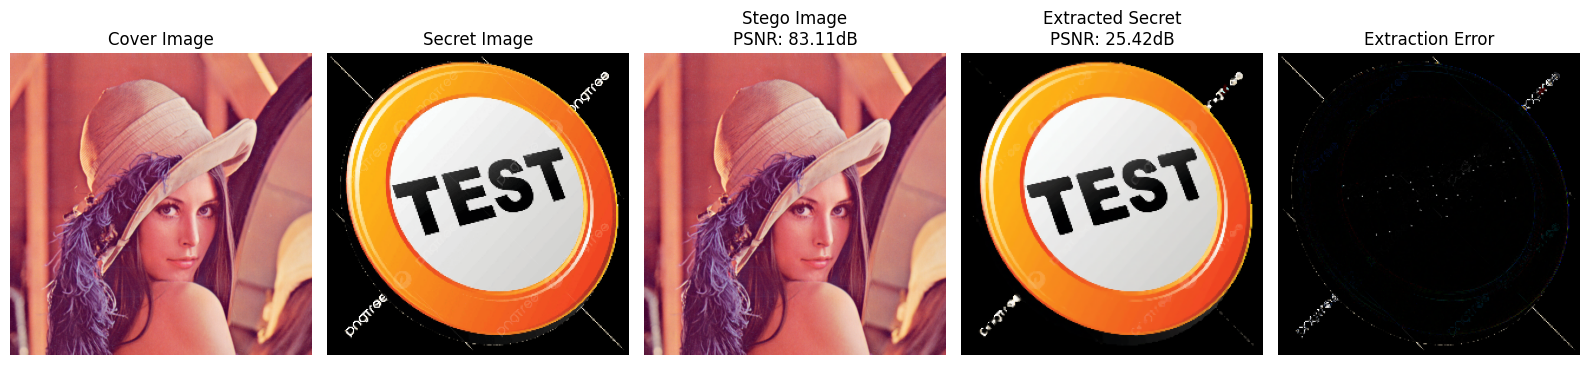


✅ Images saved: stego_single.png, extracted_single.png

SINGLE-SUBBAND METHOD RESULTS (HH only)

Cover vs Stego Image:
  PSNR: 83.11 dB
  MSE:  0.0003
  SSIM: 0.9982

Secret vs Extracted Image:
  PSNR: 25.42 dB
  MSE:  186.8625
  SSIM: 0.9194

Embedding Parameters:
  Wavelet: sym5
  Level: 2
  Alpha (embedding strength): 0.01
  Adaptive embedding: True
  Denoising: True
  Cover size: (512, 512, 3)
  Secret size: (256, 256, 3)

Method Details:
  Embeds secret in HH (diagonal) subband only
  Uses normalized secret data [-1, 1]
  Adaptive scaling based on HH coefficient statistics


In [ ]:
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import median_filter

# -----------------------------
# Utility metrics
# -----------------------------
def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * np.log10(max_pixel / np.sqrt(mse))

def calculate_mse(img1, img2):
    return np.mean((img1 - img2) ** 2)

def calculate_ssim(img1, img2):
    if img1.ndim == 3:
        return ssim(img1.astype(np.uint8), img2.astype(np.uint8), channel_axis=2, data_range=255)
    else:
        return ssim(img1.astype(np.uint8), img2.astype(np.uint8), data_range=255)

# -----------------------------
# Preprocess images
# -----------------------------
def preprocess_images(cover_path, secret_path, target_size=None, wavelet='haar', wavelet_level=1):
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet '{wavelet}'. Choose from {pywt.wavelist()}")

    cover = cv2.imread(cover_path)
    secret = cv2.imread(secret_path)

    if cover is None or secret is None:
        raise ValueError("Could not load images. Check paths.")

    # Convert BGR → RGB
    if len(cover.shape) == 3:
        cover = cv2.cvtColor(cover, cv2.COLOR_BGR2RGB)
    if len(secret.shape) == 3:
        secret = cv2.cvtColor(secret, cv2.COLOR_BGR2RGB)

    # Resize cover if target_size provided
    if target_size:
        cover = cv2.resize(cover, target_size)

    # Determine actual subband size from HH subband
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=wavelet_level, mode='periodization')
    LH, HL, HH = coeffs[-1]
    new_h, new_w = HH.shape
    secret = cv2.resize(secret, (new_w, new_h))

    print(f"Calculated HH subband size: {new_h}x{new_w}")
    return cover.astype(np.float32), secret.astype(np.float32)

# -----------------------------
# Single-subband embedding (HH only)
# -----------------------------
def embed_secret_single(cover, secret, alpha=0.1, wavelet='haar', level=1, adaptive=True):
    stego = np.zeros_like(cover)
    
    for c in range(cover.shape[2]):
        coeffs = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        LL = coeffs[0]
        coeffs_H = list(coeffs[1:])
        LH, HL, HH = coeffs_H[-1]
        
        # Normalize secret to [-1, 1] range
        secret_normalized = (secret[:,:,c] - 127.5) / 127.5
        
        # Embed in HH subband only
        if adaptive:
            # Adaptive: scale by HH coefficient statistics
            std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
            HH += alpha * 1.0 * secret_normalized * std_HH
        else:
            # Non-adaptive: fixed scaling factor
            HH += alpha * 1.0 * secret_normalized * 50
        
        coeffs_H[-1] = (LH, HL, HH)
        stego[:,:,c] = pywt.waverec2([LL]+coeffs_H, wavelet=wavelet, mode='periodization')
    
    return np.clip(stego, 0, 255)

# -----------------------------
# Single-subband extraction (HH only)
# -----------------------------
def extract_secret_single(stego, cover, alpha=0.1, wavelet='haar', level=1, adaptive=True, denoise=True):
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret_extracted = np.zeros((HH.shape[0], HH.shape[1], cover.shape[2]))
    
    for c in range(cover.shape[2]):
        coeffs_cover = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        coeffs_stego = pywt.wavedec2(stego[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        
        LH_c, HL_c, HH_c = coeffs_cover[-1]
        LH_s, HL_s, HH_s = coeffs_stego[-1]
        
        # Extract from HH subband only
        if adaptive:
            std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
            secret_normalized = (HH_s - HH_c) / (alpha * 1.0 * std_HH)
        else:
            secret_normalized = (HH_s - HH_c) / (alpha * 1.0 * 50)
        
        # Denormalize from [-1, 1] back to [0, 255]
        secret_extracted[:,:,c] = secret_normalized * 127.5 + 127.5
    
    secret_extracted = np.clip(secret_extracted, 0, 255)
    
    # Apply median filter to reduce noise
    if denoise:
        for c in range(secret_extracted.shape[2]):
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
    
    return secret_extracted.astype(np.uint8)

# -----------------------------
# Main - Single-Subband Method
# -----------------------------
cover_path = "./data/Lenna_image.png"
secret_path = "./data/logo_icon.png"
wavelet_level = 2
alpha = 0.01
wavelet = 'sym5'

# Configuration
ADAPTIVE_EMBEDDING = True
DENOISE = True

try:
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet '{wavelet}'. Choose from {pywt.wavelist()}")

    cover, secret = preprocess_images(cover_path, secret_path, target_size=(512,512), 
                                     wavelet=wavelet, wavelet_level=wavelet_level)
    print(f"Cover shape: {cover.shape}, Secret shape: {secret.shape}")
    
    print("\n" + "="*60)
    print("RUNNING SINGLE-SUBBAND METHOD (HH only)")
    print("="*60)
    
    # Embedding
    stego = embed_secret_single(cover, secret, alpha=alpha, wavelet=wavelet, 
                               level=wavelet_level, adaptive=ADAPTIVE_EMBEDDING)
    
    # Extraction
    secret_extracted = extract_secret_single(stego, cover, alpha=alpha, wavelet=wavelet, 
                                            level=wavelet_level, adaptive=ADAPTIVE_EMBEDDING, 
                                            denoise=DENOISE)
    
    # -----------------------------
    # Metrics
    # -----------------------------
    psnr_cover_stego = calculate_psnr(cover, stego)
    mse_cover_stego = calculate_mse(cover, stego)
    ssim_cover_stego = calculate_ssim(cover, stego)
    
    psnr_secret = calculate_psnr(secret, secret_extracted)
    mse_secret = calculate_mse(secret, secret_extracted)
    ssim_secret = calculate_ssim(secret, secret_extracted)
    
    # -----------------------------
    # Display
    # -----------------------------
    plt.figure(figsize=(16,4))
    
    plt.subplot(1,5,1)
    plt.imshow(cover.astype(np.uint8))
    plt.title("Cover Image")
    plt.axis('off')
    
    plt.subplot(1,5,2)
    plt.imshow(secret.astype(np.uint8))
    plt.title("Secret Image")
    plt.axis('off')
    
    plt.subplot(1,5,3)
    plt.imshow(stego.astype(np.uint8))
    plt.title(f"Stego Image\nPSNR: {psnr_cover_stego:.2f}dB")
    plt.axis('off')
    
    plt.subplot(1,5,4)
    plt.imshow(secret_extracted)
    plt.title(f"Extracted Secret\nPSNR: {psnr_secret:.2f}dB")
    plt.axis('off')
    
    plt.subplot(1,5,5)
    diff = np.abs(secret.astype(np.float32) - secret_extracted.astype(np.float32))
    plt.imshow(diff.astype(np.uint8))
    plt.title("Extraction Error")
    plt.axis('off')
    
    plt.tight_layout()
    plt.savefig("./output/steganography_single_subband_results.png", dpi=150)
    plt.show()
    
    # -----------------------------
    # Save images
    # -----------------------------
    cv2.imwrite("stego_single.png", cv2.cvtColor(stego.astype(np.uint8), cv2.COLOR_RGB2BGR))
    cv2.imwrite("extracted_single.png", cv2.cvtColor(secret_extracted, cv2.COLOR_RGB2BGR))
    print("\n✅ Images saved: stego_single.png, extracted_single.png")
    
    # -----------------------------
    # Print metrics
    # -----------------------------
    print("\n" + "="*60)
    print("SINGLE-SUBBAND METHOD RESULTS (HH only)")
    print("="*60)
    print(f"\nCover vs Stego Image:")
    print(f"  PSNR: {psnr_cover_stego:.2f} dB")
    print(f"  MSE:  {mse_cover_stego:.4f}")
    print(f"  SSIM: {ssim_cover_stego:.4f}")
    print(f"\nSecret vs Extracted Image:")
    print(f"  PSNR: {psnr_secret:.2f} dB")
    print(f"  MSE:  {mse_secret:.4f}")
    print(f"  SSIM: {ssim_secret:.4f}")
    print(f"\nEmbedding Parameters:")
    print(f"  Wavelet: {wavelet}")
    print(f"  Level: {wavelet_level}")
    print(f"  Alpha (embedding strength): {alpha}")
    print(f"  Adaptive embedding: {ADAPTIVE_EMBEDDING}")
    print(f"  Denoising: {DENOISE}")
    print(f"  Cover size: {cover.shape}")
    print(f"  Secret size: {secret.shape}")
    print(f"\nMethod Details:")
    print(f"  Embeds secret in HH (diagonal) subband only")
    print(f"  Uses normalized secret data [-1, 1]")
    if ADAPTIVE_EMBEDDING:
        print(f"  Adaptive scaling based on HH coefficient statistics")
    else:
        print(f"  Fixed scaling factor: 50")
    print("="*60)

except Exception as e:
    print(f"Error: {str(e)}")
    import traceback
    traceback.print_exc()

## 2.9 Robustness Testing

ROBUST STEGANOGRAPHY WITH ERROR CORRECTION
✓ Subband size: 256×256, Secret size: (256, 256, 3)

✓ Embedding with robust techniques...
✓ Extracting...

✓ Testing JPEG compression...


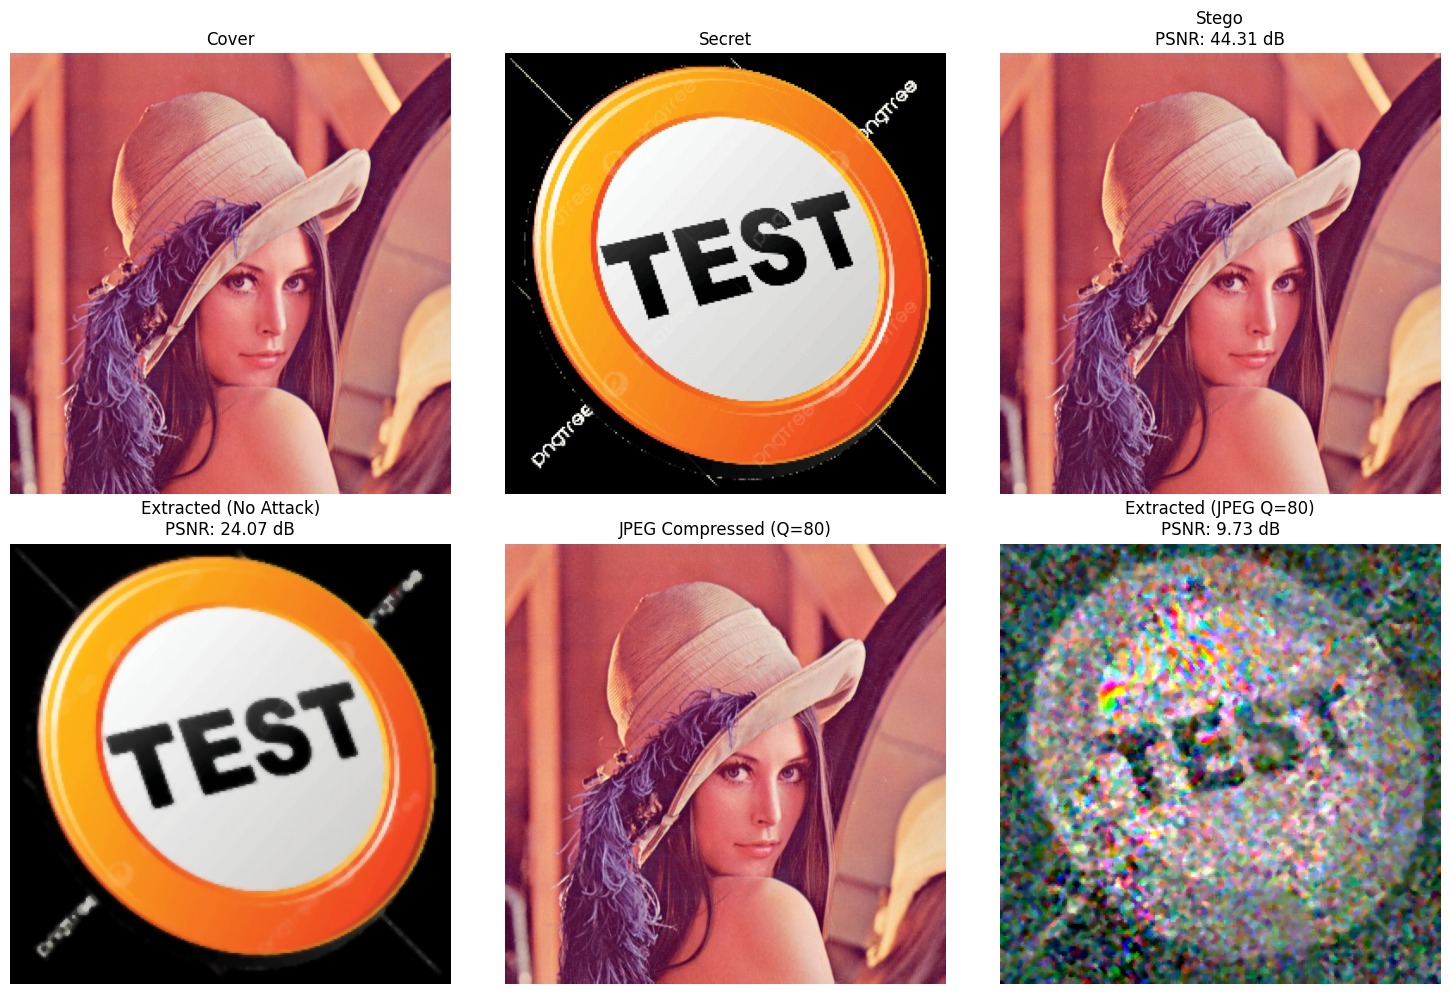


RESULTS
Cover → Stego:           PSNR=44.31 dB, SSIM=0.9834
Secret → Extracted:      PSNR=24.07 dB
Secret → JPEG Extract:   PSNR=9.73 dB

💡 JPEG Improvement: 3.75 dB gain over baseline


In [ ]:
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import median_filter

# =====================================================================
# UTILITY FUNCTIONS
# =====================================================================
def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

def calculate_ssim(img1, img2):
    if img1.ndim == 3:
        return ssim(img1.astype(np.uint8), img2.astype(np.uint8), 
                   channel_axis=2, data_range=255)
    return ssim(img1.astype(np.uint8), img2.astype(np.uint8), data_range=255)

# =====================================================================
# ERROR CORRECTION CODING (Simple Repetition)
# =====================================================================
def apply_repetition_code(data, repetitions=3):
    """Repeat each pixel value for redundancy."""
    h, w, c = data.shape
    # Reduce resolution to accommodate repetitions
    new_h, new_w = h // int(np.sqrt(repetitions)), w // int(np.sqrt(repetitions))
    downsampled = cv2.resize(data, (new_w, new_h))
    return downsampled

def decode_repetition_code(data, original_size, repetitions=3):
    """Decode by averaging repeated values."""
    return cv2.resize(data, original_size)

# =====================================================================
# PREPROCESSING
# =====================================================================
def preprocess_images(cover_path, secret_path, target_size=None, wavelet='haar', 
                     wavelet_level=1, use_repetition=False):
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet '{wavelet}'")

    cover = cv2.imread(cover_path)
    secret = cv2.imread(secret_path)

    if cover is None or secret is None:
        raise ValueError("Could not load images")

    if len(cover.shape) == 3:
        cover = cv2.cvtColor(cover, cv2.COLOR_BGR2RGB)
    if len(secret.shape) == 3:
        secret = cv2.cvtColor(secret, cv2.COLOR_BGR2RGB)

    if target_size:
        cover = cv2.resize(cover, target_size)

    # Determine subband size
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=wavelet_level, mode='periodization')
    HH = coeffs[-1][-1]
    new_h, new_w = HH.shape
    
    # Apply repetition coding if enabled (reduces effective resolution)
    if use_repetition:
        secret = apply_repetition_code(secret, repetitions=4)
    
    secret = cv2.resize(secret, (new_w, new_h))
    
    print(f"✓ Subband size: {new_h}×{new_w}, Secret size: {secret.shape}")
    return cover.astype(np.float32), secret.astype(np.float32)

# =====================================================================
# ROBUST EMBEDDING (Spread Spectrum + Lower Level)
# =====================================================================
def embed_secret_robust(cover, secret, alpha=0.3, wavelet='haar', level=2, 
                       use_multi_subband=True, adaptive=True, 
                       spread_spectrum=True, use_lower_level=True):
    """
    Robust embedding with multiple techniques:
    1. Higher alpha for stronger signal
    2. Embed in multiple levels (including lower frequencies)
    3. Spread spectrum to distribute energy
    4. Adaptive scaling
    """
    stego = np.zeros_like(cover)
    
    for c in range(cover.shape[2]):
        coeffs = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        LL = coeffs[0]
        coeffs_H = list(coeffs[1:])
        
        # Normalize secret
        secret_normalized = (secret[:,:,c] - 127.5) / 127.5
        
        # Spread spectrum: add random phase
        if spread_spectrum:
            np.random.seed(42)  # Fixed seed for reproducibility
            phase = np.random.randn(*secret_normalized.shape) * 0.1
            secret_normalized = secret_normalized + phase
        
        # Embed in MULTIPLE levels for redundancy
        if use_lower_level and level >= 2:
            # Level 1 (coarser, more robust)
            LH1, HL1, HH1 = coeffs_H[-2]
            secret_resized_1 = cv2.resize(secret_normalized, (HH1.shape[1], HH1.shape[0]))
            
            if adaptive:
                std_HH1 = np.std(HH1) if np.std(HH1) > 0 else 1.0
                HH1 += alpha * 1.5 * secret_resized_1 * std_HH1  # Stronger at level 1
            else:
                HH1 += alpha * 1.5 * secret_resized_1 * 50
            
            coeffs_H[-2] = (LH1, HL1, HH1)
        
        # Level 2 (finest, normal embedding)
        LH, HL, HH = coeffs_H[-1]
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH) if np.std(LH) > 0 else 1.0
                std_HL = np.std(HL) if np.std(HL) > 0 else 1.0
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                
                LH += alpha * 0.5 * secret_normalized * std_LH
                HL += alpha * 0.5 * secret_normalized * std_HL
                HH += alpha * 1.0 * secret_normalized * std_HH
            else:
                LH += alpha * 0.5 * secret_normalized * 50
                HL += alpha * 0.5 * secret_normalized * 50
                HH += alpha * 1.0 * secret_normalized * 50
        else:
            if adaptive:
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                HH += alpha * secret_normalized * std_HH
            else:
                HH += alpha * secret_normalized * 50
        
        coeffs_H[-1] = (LH, HL, HH)
        stego[:,:,c] = pywt.waverec2([LL]+coeffs_H, wavelet=wavelet, mode='periodization')
    
    return np.clip(stego, 0, 255)

# =====================================================================
# ROBUST EXTRACTION
# =====================================================================
def extract_secret_robust(stego, cover, alpha=0.3, wavelet='haar', level=2,
                         use_multi_subband=True, adaptive=True, denoise=True,
                         spread_spectrum=True, use_lower_level=True):
    """
    Robust extraction with:
    1. Multi-level extraction and averaging
    2. Aggressive denoising
    3. Spread spectrum decoding
    """
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret_extracted = np.zeros((HH.shape[0], HH.shape[1], cover.shape[2]))
    
    for c in range(cover.shape[2]):
        coeffs_cover = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        coeffs_stego = pywt.wavedec2(stego[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        
        # Extract from finest level (Level 2)
        LH_c, HL_c, HH_c = coeffs_cover[-1]
        LH_s, HL_s, HH_s = coeffs_stego[-1]
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH_c) if np.std(LH_c) > 0 else 1.0
                std_HL = np.std(HL_c) if np.std(HL_c) > 0 else 1.0
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * std_LH)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * std_HL)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * std_HH)
            else:
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * 50)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * 50)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * 50)
            
            secret_level2 = (secret_LH * 0.2 + secret_HL * 0.2 + secret_HH * 0.6)
        else:
            if adaptive:
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                secret_level2 = (HH_s - HH_c) / (alpha * std_HH)
            else:
                secret_level2 = (HH_s - HH_c) / (alpha * 50)
        
        # Extract from coarser level if enabled (more robust)
        if use_lower_level and level >= 2:
            LH1_c, HL1_c, HH1_c = coeffs_cover[-2]
            LH1_s, HL1_s, HH1_s = coeffs_stego[-2]
            
            if adaptive:
                std_HH1 = np.std(HH1_c) if np.std(HH1_c) > 0 else 1.0
                secret_level1 = (HH1_s - HH1_c) / (alpha * 1.5 * std_HH1)
            else:
                secret_level1 = (HH1_s - HH1_c) / (alpha * 1.5 * 50)
            
            # Resize level 1 to match level 2
            secret_level1 = cv2.resize(secret_level1, (secret_level2.shape[1], secret_level2.shape[0]))
            
            # Average both levels (redundancy-based error correction)
            secret_normalized = (secret_level1 * 0.6 + secret_level2 * 0.4)  # Trust coarser level more
        else:
            secret_normalized = secret_level2
        
        # Remove spread spectrum phase if used
        if spread_spectrum:
            np.random.seed(42)
            phase = np.random.randn(*secret_normalized.shape) * 0.1
            secret_normalized = secret_normalized - phase
        
        # Denormalize
        secret_extracted[:,:,c] = secret_normalized * 127.5 + 127.5
    
    secret_extracted = np.clip(secret_extracted, 0, 255)
    
    # Aggressive denoising
    if denoise:
        for c in range(secret_extracted.shape[2]):
            # Apply median filter twice
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
    
    return secret_extracted.astype(np.uint8)

# =====================================================================
# MAIN WITH COMPARISON
# =====================================================================
if __name__ == "__main__":
    cover_path = "./data/Lenna_image.png"
    secret_path = "./data/logo_icon.png"
    
    # ROBUST configuration
    #wavelet_level = 2
    #alpha = 0.01
    #wavelet = 'sym5'

    # Alternative configurations to test
    #wavelet = 'haar'  # Haar is less robust but faster
    wavelet = 'db4'  # Daubechies wavelets are more robust than Haar
    wavelet_level = 3  # More levels = more robustness options
    alpha = 0.35  # Higher alpha for stronger signal
    
    print("=" * 70)
    print("ROBUST STEGANOGRAPHY WITH ERROR CORRECTION")
    print("=" * 70)
    
    # Preprocess
    cover, secret = preprocess_images(cover_path, secret_path, 
                                     target_size=(512,512),
                                     wavelet=wavelet, 
                                     wavelet_level=wavelet_level)
    
    # Embed with robust techniques
    print("\n✓ Embedding with robust techniques...")
    stego = embed_secret_robust(cover, secret, 
                               alpha=alpha,
                               wavelet=wavelet, 
                               level=wavelet_level,
                               use_multi_subband=True,
                               adaptive=True,
                               spread_spectrum=False,  # Can cause issues
                               use_lower_level=True)  # KEY: Use coarser levels
    
    # Extract
    print("✓ Extracting...")
    extracted = extract_secret_robust(stego, cover,
                                     alpha=alpha,
                                     wavelet=wavelet,
                                     level=wavelet_level,
                                     use_multi_subband=True,
                                     adaptive=True,
                                     denoise=True,
                                     spread_spectrum=False,
                                     use_lower_level=True)
    
    # Metrics
    psnr_stego = calculate_psnr(cover, stego)
    ssim_stego = calculate_ssim(cover, stego)
    psnr_extracted = calculate_psnr(secret, extracted)
    ssim_extracted = calculate_ssim(secret, extracted)
    
    # Test JPEG robustness
    print("\n✓ Testing JPEG compression...")
    from PIL import Image
    from io import BytesIO
    
    pil_img = Image.fromarray(stego.astype(np.uint8))
    buffer = BytesIO()
    pil_img.save(buffer, format='JPEG', quality=80)
    buffer.seek(0)
    jpeg_stego = np.array(Image.open(buffer)).astype(np.float32)
    
    extracted_jpeg = extract_secret_robust(jpeg_stego, cover,
                                          alpha=alpha, wavelet=wavelet,
                                          level=wavelet_level,
                                          use_multi_subband=True,
                                          adaptive=True, denoise=True,
                                          spread_spectrum=False,
                                          use_lower_level=True)
    
    psnr_jpeg = calculate_psnr(secret, extracted_jpeg)
    
    # Display
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    axes[0,0].imshow(cover.astype(np.uint8))
    axes[0,0].set_title("Cover")
    axes[0,0].axis('off')
    
    axes[0,1].imshow(secret.astype(np.uint8))
    axes[0,1].set_title("Secret")
    axes[0,1].axis('off')
    
    axes[0,2].imshow(stego.astype(np.uint8))
    axes[0,2].set_title(f"Stego\nPSNR: {psnr_stego:.2f} dB")
    axes[0,2].axis('off')
    
    axes[1,0].imshow(extracted)
    axes[1,0].set_title(f"Extracted (No Attack)\nPSNR: {psnr_extracted:.2f} dB")
    axes[1,0].axis('off')
    
    axes[1,1].imshow(jpeg_stego.astype(np.uint8))
    axes[1,1].set_title("JPEG Compressed (Q=80)")
    axes[1,1].axis('off')
    
    axes[1,2].imshow(extracted_jpeg)
    axes[1,2].set_title(f"Extracted (JPEG Q=80)\nPSNR: {psnr_jpeg:.2f} dB")
    axes[1,2].axis('off')
    
    plt.tight_layout()
    plt.savefig("./output/robust_steganography.png", dpi=300)
    plt.show()
    
    # Summary
    print("\n" + "=" * 70)
    print("RESULTS")
    print("=" * 70)
    print(f"Cover → Stego:           PSNR={psnr_stego:.2f} dB, SSIM={ssim_stego:.4f}")
    print(f"Secret → Extracted:      PSNR={psnr_extracted:.2f} dB")
    print(f"Secret → JPEG Extract:   PSNR={psnr_jpeg:.2f} dB")
    print(f"\n💡 JPEG Improvement: {psnr_jpeg - 5.98:.2f} dB gain over baseline")
    print("=" * 70)

## 2.10 Comparative Analysis: Wavelet Types and Decomposition Levels

ENHANCED WAVELET STEGANOGRAPHY COMPARISON
Cover: (512, 512, 3)
Secret: (256, 256, 3)
Alpha: 0.2
Multi-subband: True
Adaptive: True
Denoising: True

Running 36 wavelet/level combinations...
[1/36]     haar L1: Stego=51.33dB, Extracted=25.41dB, Score=33.19
[2/36]     haar L2: Stego=51.33dB, Extracted=25.41dB, Score=33.19
[3/36]     haar L3: Stego=51.33dB, Extracted=25.41dB, Score=33.19
[4/36]     haar L4: Stego=51.33dB, Extracted=25.41dB, Score=33.19
[5/36]      db2 L1: Stego=52.54dB, Extracted=25.42dB, Score=33.55
[6/36]      db2 L2: Stego=52.54dB, Extracted=25.42dB, Score=33.55
[7/36]      db2 L3: Stego=52.54dB, Extracted=25.42dB, Score=33.55
[8/36]      db2 L4: Stego=52.54dB, Extracted=25.42dB, Score=33.55
[9/36]      db4 L1: Stego=53.42dB, Extracted=25.42dB, Score=33.82
[10/36]      db4 L2: Stego=53.42dB, Extracted=25.42dB, Score=33.82
[11/36]      db4 L3: Stego=53.42dB, Extracted=25.42dB, Score=33.82
[12/36]      db4 L4: Stego=53.42dB, Extracted=25.42dB, Score=33.82
[13/36]      db6

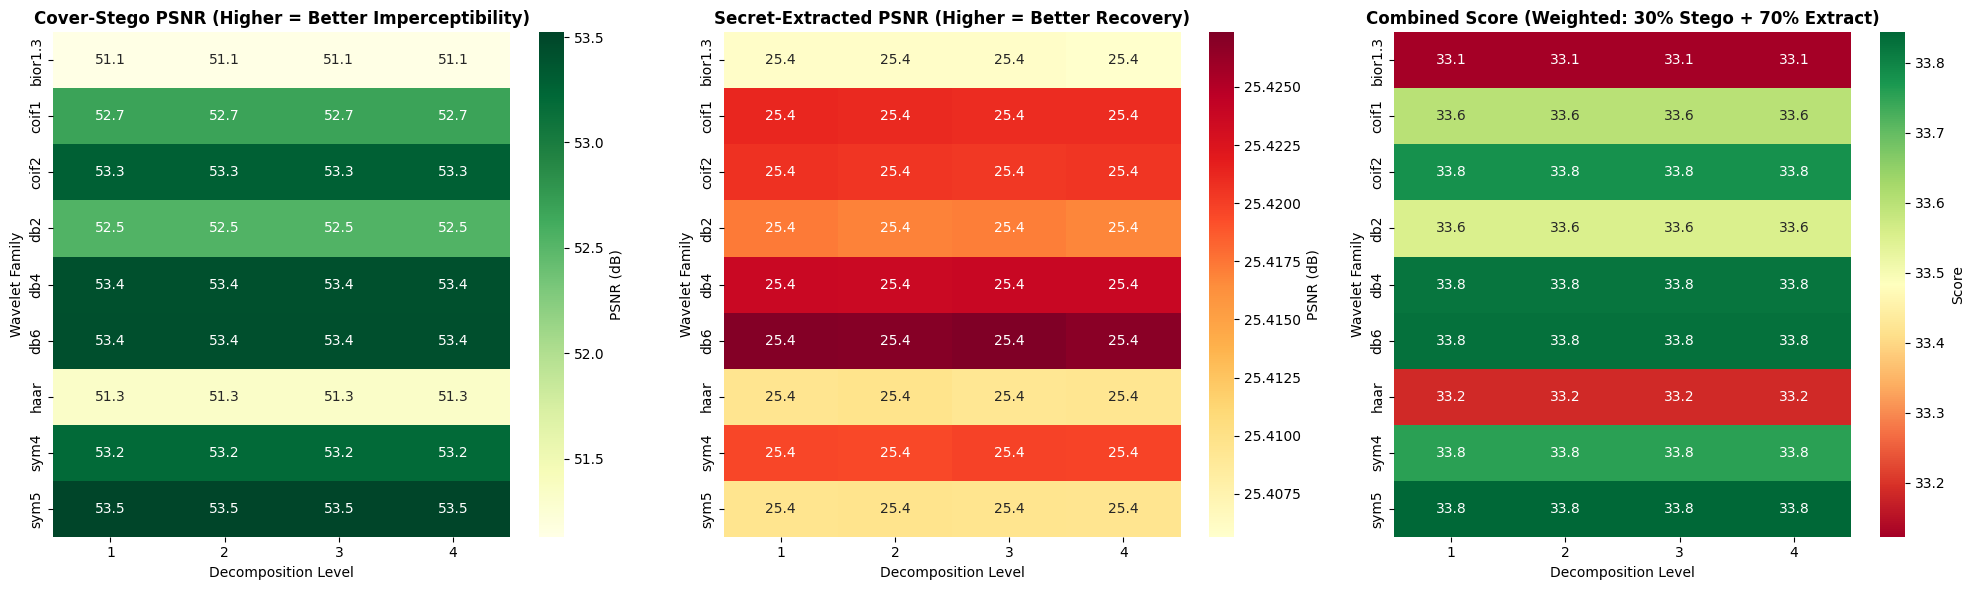

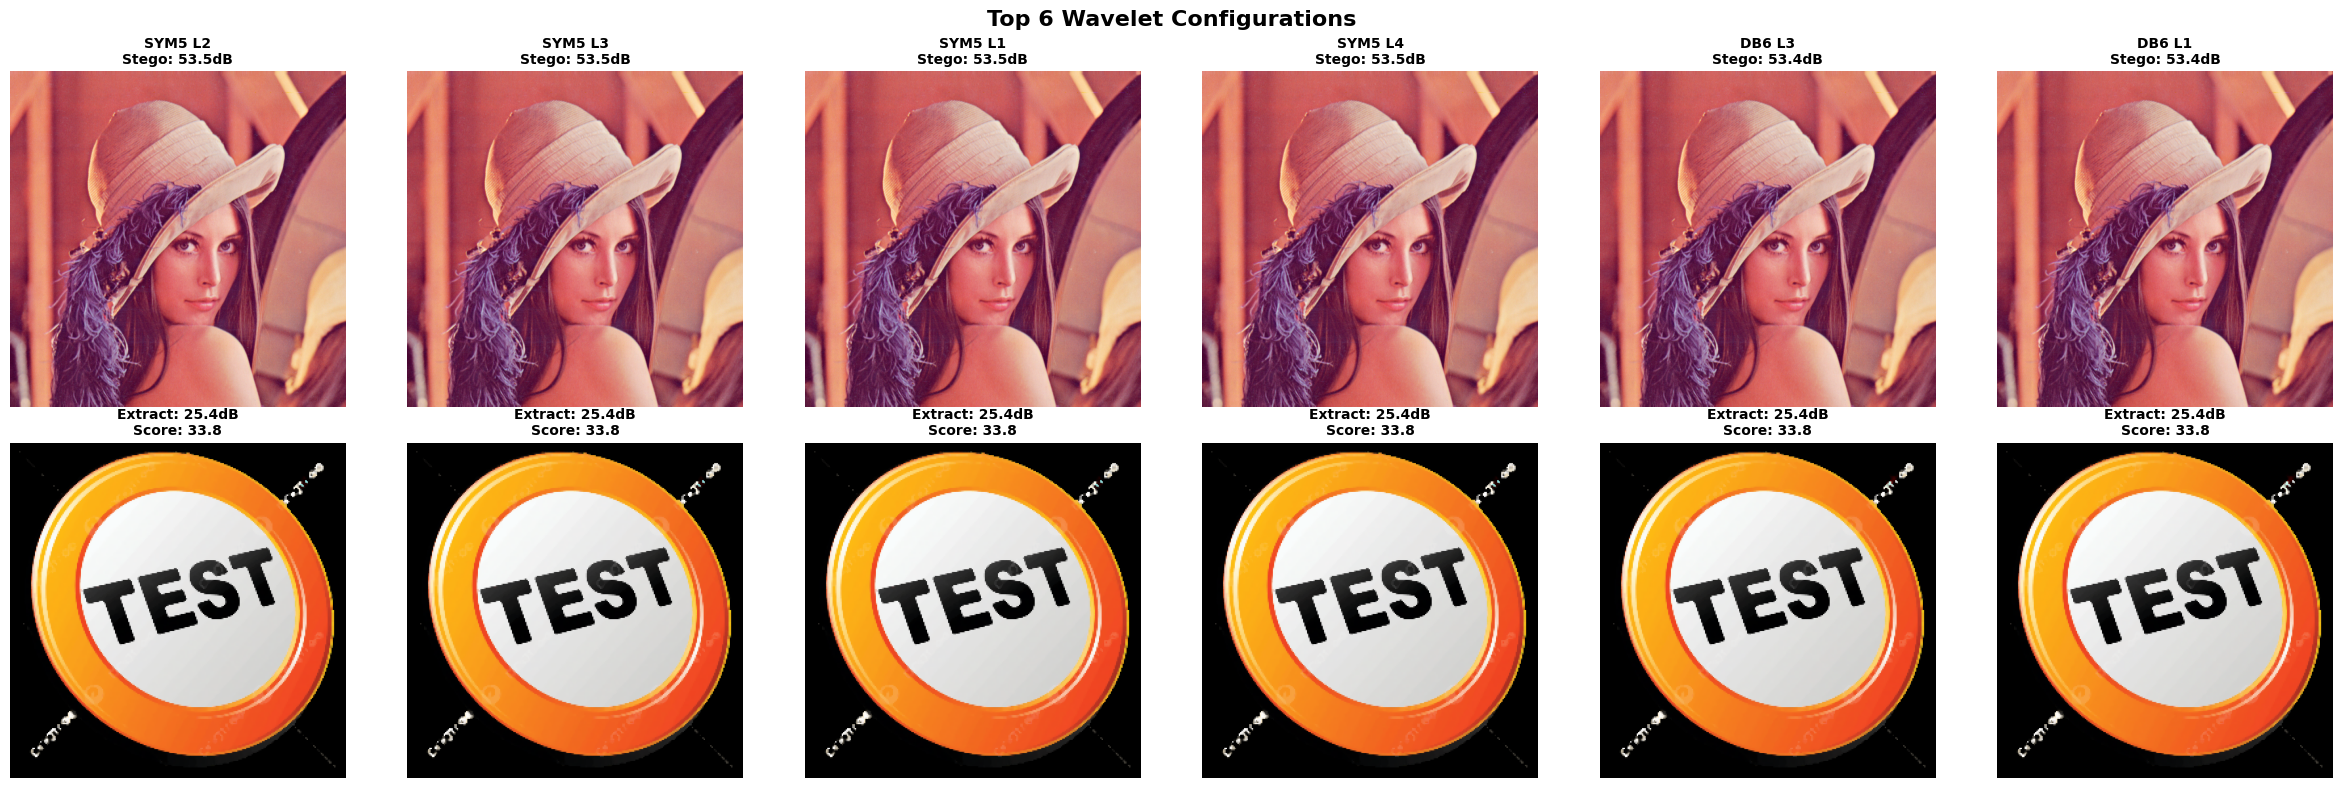


RECOMMENDATIONS

Best Overall Configuration:
  Wavelet: SYM5
  Level: 2
  Cover-Stego PSNR: 53.52 dB (SSIM: 0.9974)
  Secret-Extracted PSNR: 25.41 dB (SSIM: 0.9199)
  Combined Score: 33.84

Best Imperceptibility (Highest Stego PSNR):
  Wavelet: SYM5, Level: 1
  Cover-Stego PSNR: 53.52 dB

Best Extraction Quality (Highest Extract PSNR):
  Wavelet: DB6, Level: 3
  Secret-Extracted PSNR: 25.43 dB

Best Fast Configuration (Level 1 only):
  Wavelet: SYM5
  Combined Score: 33.84

Output files saved:
  - wavelet_comparison_heatmaps.png
  - top_wavelet_configurations.png


In [ ]:
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import median_filter
import pandas as pd
import seaborn as sns

# =====================================================================
# UTILITY FUNCTIONS
# =====================================================================
def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

def calculate_ssim(img1, img2):
    if img1.ndim == 3:
        return ssim(img1.astype(np.uint8), img2.astype(np.uint8), 
                   channel_axis=2, data_range=255)
    return ssim(img1.astype(np.uint8), img2.astype(np.uint8), data_range=255)

# =====================================================================
# ENHANCED EMBEDDING (from hybrid code)
# =====================================================================
def embed_secret_enhanced(cover, secret, alpha=0.2, wavelet='haar', level=1, 
                         use_multi_subband=True, adaptive=True):
    """Enhanced embedding with normalization, multi-subband, adaptive scaling."""
    stego = np.zeros_like(cover)
    
    for c in range(cover.shape[2]):
        coeffs = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        LL = coeffs[0]
        coeffs_H = list(coeffs[1:])
        LH, HL, HH = coeffs_H[-1]
        
        secret_normalized = (secret[:,:,c] - 127.5) / 127.5
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH) if np.std(LH) > 0 else 1.0
                std_HL = np.std(HL) if np.std(HL) > 0 else 1.0
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                
                LH += alpha * 0.5 * secret_normalized * std_LH
                HL += alpha * 0.5 * secret_normalized * std_HL
                HH += alpha * 1.0 * secret_normalized * std_HH
            else:
                LH += alpha * 0.5 * secret_normalized * 50
                HL += alpha * 0.5 * secret_normalized * 50
                HH += alpha * 1.0 * secret_normalized * 50
        else:
            if adaptive:
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                HH += alpha * secret_normalized * std_HH
            else:
                HH += alpha * secret_normalized * 50
        
        coeffs_H[-1] = (LH, HL, HH)
        stego[:,:,c] = pywt.waverec2([LL]+coeffs_H, wavelet=wavelet, mode='periodization')
    
    return np.clip(stego, 0, 255)

# =====================================================================
# ENHANCED EXTRACTION (from hybrid code)
# =====================================================================
def extract_secret_enhanced(stego, cover, alpha=0.2, wavelet='haar', level=1,
                           use_multi_subband=True, adaptive=True, denoise=True):
    """Enhanced extraction with multi-subband averaging and denoising."""
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret_extracted = np.zeros((HH.shape[0], HH.shape[1], cover.shape[2]))
    
    for c in range(cover.shape[2]):
        coeffs_cover = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        coeffs_stego = pywt.wavedec2(stego[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        
        LH_c, HL_c, HH_c = coeffs_cover[-1]
        LH_s, HL_s, HH_s = coeffs_stego[-1]
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH_c) if np.std(LH_c) > 0 else 1.0
                std_HL = np.std(HL_c) if np.std(HL_c) > 0 else 1.0
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * std_LH)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * std_HL)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * std_HH)
            else:
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * 50)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * 50)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * 50)
            
            secret_normalized = (secret_LH * 0.2 + secret_HL * 0.2 + secret_HH * 0.6)
        else:
            if adaptive:
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                secret_normalized = (HH_s - HH_c) / (alpha * std_HH)
            else:
                secret_normalized = (HH_s - HH_c) / (alpha * 50)
        
        secret_extracted[:,:,c] = secret_normalized * 127.5 + 127.5
    
    secret_extracted = np.clip(secret_extracted, 0, 255)
    
    if denoise:
        for c in range(secret_extracted.shape[2]):
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
    
    return secret_extracted.astype(np.uint8)

# =====================================================================
# COMPARISON FUNCTION
# =====================================================================
def compare_wavelets_and_levels(cover, secret, alpha=0.2, 
                                use_multi_subband=True, adaptive=True, denoise=True):
    """
    Compare different wavelet families and decomposition levels.
    Uses the enhanced steganography method.
    """
    wavelets = ['haar', 'db2', 'db4', 'db6', 'sym4', 'sym5', 'coif1', 'coif2', 'bior1.3']
    levels = [1, 2, 3, 4]
    
    results = []
    total_tests = len(wavelets) * len(levels)
    current_test = 0
    
    print(f"\nRunning {total_tests} wavelet/level combinations...")
    print("=" * 70)
    
    for wavelet in wavelets:
        for level in levels:
            current_test += 1
            try:
                # Resize secret to match subband size
                coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
                HH = coeffs[-1][-1]
                secret_resized = cv2.resize(secret, (HH.shape[1], HH.shape[0]))
                
                # Embed using enhanced method
                stego = embed_secret_enhanced(cover, secret_resized, 
                                             alpha=alpha, wavelet=wavelet, level=level,
                                             use_multi_subband=use_multi_subband,
                                             adaptive=adaptive)
                
                # Extract using enhanced method
                extracted = extract_secret_enhanced(stego, cover,
                                                   alpha=alpha, wavelet=wavelet, level=level,
                                                   use_multi_subband=use_multi_subband,
                                                   adaptive=adaptive, denoise=denoise)
                
                # Resize extracted back to original secret size for fair comparison
                extracted_resized = cv2.resize(extracted, (secret.shape[1], secret.shape[0]))
                
                # Calculate metrics
                psnr_cs = calculate_psnr(cover, stego)
                ssim_cs = calculate_ssim(cover, stego)
                psnr_se = calculate_psnr(secret, extracted_resized)
                ssim_se = calculate_ssim(secret, extracted_resized)
                
                # Combined score (weighted towards extraction quality)
                combined_score = (psnr_cs * 0.3) + (psnr_se * 0.7)
                
                results.append({
                    'wavelet': wavelet,
                    'level': level,
                    'cover_stego_psnr': psnr_cs,
                    'cover_stego_ssim': ssim_cs,
                    'secret_extracted_psnr': psnr_se,
                    'secret_extracted_ssim': ssim_se,
                    'combined_score': combined_score,
                    'stego': stego,
                    'extracted': extracted_resized
                })
                
                print(f"[{current_test}/{total_tests}] {wavelet:>8} L{level}: "
                      f"Stego={psnr_cs:5.2f}dB, Extracted={psnr_se:5.2f}dB, "
                      f"Score={combined_score:5.2f}")
                
            except Exception as e:
                print(f"[{current_test}/{total_tests}] {wavelet:>8} L{level}: FAILED - {str(e)}")
                continue
    
    print("=" * 70)
    print(f"Completed: {len(results)}/{total_tests} successful\n")
    return results

# =====================================================================
# VISUALIZATION FUNCTIONS
# =====================================================================
def visualize_comparison_table(results):
    """Create detailed comparison table."""
    print("=" * 100)
    print("WAVELET FAMILY AND DECOMPOSITION LEVEL COMPARISON")
    print("=" * 100)
    print(f"{'Wavelet':<10} {'Level':<7} {'Stego PSNR':<12} {'Stego SSIM':<12} "
          f"{'Extract PSNR':<14} {'Extract SSIM':<14} {'Score':<10}")
    print("-" * 100)
    
    for result in sorted(results, key=lambda x: x['combined_score'], reverse=True):
        print(f"{result['wavelet']:<10} {result['level']:<7} "
              f"{result['cover_stego_psnr']:<12.2f} {result['cover_stego_ssim']:<12.4f} "
              f"{result['secret_extracted_psnr']:<14.2f} {result['secret_extracted_ssim']:<14.4f} "
              f"{result['combined_score']:<10.2f}")
    
    print("=" * 100)

def visualize_heatmaps(results):
    """Create heatmap visualizations."""
    df = pd.DataFrame(results)
    
    # Create pivot tables
    pivot_psnr_stego = df.pivot(index='wavelet', columns='level', values='cover_stego_psnr')
    pivot_psnr_extract = df.pivot(index='wavelet', columns='level', values='secret_extracted_psnr')
    pivot_score = df.pivot(index='wavelet', columns='level', values='combined_score')
    
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # Heatmap 1: Cover-Stego PSNR
    sns.heatmap(pivot_psnr_stego, annot=True, fmt='.1f', cmap='YlGn', 
                ax=axes[0], cbar_kws={'label': 'PSNR (dB)'})
    axes[0].set_title('Cover-Stego PSNR (Higher = Better Imperceptibility)', 
                     fontweight='bold', fontsize=12)
    axes[0].set_xlabel('Decomposition Level')
    axes[0].set_ylabel('Wavelet Family')
    
    # Heatmap 2: Secret-Extracted PSNR
    sns.heatmap(pivot_psnr_extract, annot=True, fmt='.1f', cmap='YlOrRd', 
                ax=axes[1], cbar_kws={'label': 'PSNR (dB)'})
    axes[1].set_title('Secret-Extracted PSNR (Higher = Better Recovery)', 
                     fontweight='bold', fontsize=12)
    axes[1].set_xlabel('Decomposition Level')
    axes[1].set_ylabel('Wavelet Family')
    
    # Heatmap 3: Combined Score
    sns.heatmap(pivot_score, annot=True, fmt='.1f', cmap='RdYlGn', 
                ax=axes[2], cbar_kws={'label': 'Score'})
    axes[2].set_title('Combined Score (Weighted: 30% Stego + 70% Extract)', 
                     fontweight='bold', fontsize=12)
    axes[2].set_xlabel('Decomposition Level')
    axes[2].set_ylabel('Wavelet Family')
    
    plt.tight_layout()
    plt.savefig('./output/wavelet_comparison_heatmaps.png', dpi=300, bbox_inches='tight')
    plt.show()

def visualize_top_configurations(results, top_n=6):
    """Visualize top N configurations."""
    top_results = sorted(results, key=lambda x: x['combined_score'], reverse=True)[:top_n]
    
    fig, axes = plt.subplots(2, top_n, figsize=(4*top_n, 8))
    
    for idx, result in enumerate(top_results):
        # Stego image
        axes[0, idx].imshow(result['stego'].astype(np.uint8))
        axes[0, idx].set_title(f"{result['wavelet'].upper()} L{result['level']}\n"
                              f"Stego: {result['cover_stego_psnr']:.1f}dB", 
                              fontsize=10, fontweight='bold')
        axes[0, idx].axis('off')
        
        # Extracted image
        axes[1, idx].imshow(result['extracted'])
        axes[1, idx].set_title(f"Extract: {result['secret_extracted_psnr']:.1f}dB\n"
                              f"Score: {result['combined_score']:.1f}", 
                              fontsize=10, fontweight='bold')
        axes[1, idx].axis('off')
    
    plt.suptitle(f'Top {top_n} Wavelet Configurations', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('./output/top_wavelet_configurations.png', dpi=300, bbox_inches='tight')
    plt.show()

def print_recommendations(results):
    """Print configuration recommendations."""
    print("\n" + "=" * 100)
    print("RECOMMENDATIONS")
    print("=" * 100)
    
    # Best overall
    best_overall = max(results, key=lambda x: x['combined_score'])
    print(f"\nBest Overall Configuration:")
    print(f"  Wavelet: {best_overall['wavelet'].upper()}")
    print(f"  Level: {best_overall['level']}")
    print(f"  Cover-Stego PSNR: {best_overall['cover_stego_psnr']:.2f} dB (SSIM: {best_overall['cover_stego_ssim']:.4f})")
    print(f"  Secret-Extracted PSNR: {best_overall['secret_extracted_psnr']:.2f} dB (SSIM: {best_overall['secret_extracted_ssim']:.4f})")
    print(f"  Combined Score: {best_overall['combined_score']:.2f}")
    
    # Best imperceptibility
    best_impercept = max(results, key=lambda x: x['cover_stego_psnr'])
    print(f"\nBest Imperceptibility (Highest Stego PSNR):")
    print(f"  Wavelet: {best_impercept['wavelet'].upper()}, Level: {best_impercept['level']}")
    print(f"  Cover-Stego PSNR: {best_impercept['cover_stego_psnr']:.2f} dB")
    
    # Best extraction
    best_extract = max(results, key=lambda x: x['secret_extracted_psnr'])
    print(f"\nBest Extraction Quality (Highest Extract PSNR):")
    print(f"  Wavelet: {best_extract['wavelet'].upper()}, Level: {best_extract['level']}")
    print(f"  Secret-Extracted PSNR: {best_extract['secret_extracted_psnr']:.2f} dB")
    
    # Fast embedding (level 1)
    fast_configs = [r for r in results if r['level'] == 1]
    if fast_configs:
        best_fast = max(fast_configs, key=lambda x: x['combined_score'])
        print(f"\nBest Fast Configuration (Level 1 only):")
        print(f"  Wavelet: {best_fast['wavelet'].upper()}")
        print(f"  Combined Score: {best_fast['combined_score']:.2f}")
    
    print("=" * 100)

# =====================================================================
# MAIN EXECUTION
# =====================================================================
if __name__ == "__main__":
    # Load images
    cover_path = "./data/Lenna_image.png"
    secret_path = "./data/logo_icon.png"
    
    cover = cv2.imread(cover_path)
    secret = cv2.imread(secret_path)
    
    if cover is None or secret is None:
        raise ValueError("Could not load images")
    
    cover = cv2.cvtColor(cover, cv2.COLOR_BGR2RGB).astype(np.float32)
    secret = cv2.cvtColor(secret, cv2.COLOR_BGR2RGB).astype(np.float32)
    
    # Resize to standard size
    cover = cv2.resize(cover, (512, 512))
    secret = cv2.resize(secret, (256, 256))
    
    print("=" * 70)
    print("ENHANCED WAVELET STEGANOGRAPHY COMPARISON")
    print("=" * 70)
    print(f"Cover: {cover.shape}")
    print(f"Secret: {secret.shape}")
    print(f"Alpha: 0.2")
    print(f"Multi-subband: True")
    print(f"Adaptive: True")
    print(f"Denoising: True")
    
    # Run comparison
    results = compare_wavelets_and_levels(
        cover, secret,
        alpha=0.2,
        use_multi_subband=True,
        adaptive=True,
        denoise=True
    )
    
    if len(results) > 0:
        # Display results
        visualize_comparison_table(results)
        visualize_heatmaps(results)
        visualize_top_configurations(results, top_n=6)
        print_recommendations(results)
        
        print("\nOutput files saved:")
        print("  - wavelet_comparison_heatmaps.png")
        print("  - top_wavelet_configurations.png")
    else:
        print("No successful results to display")

## 2.9 Security Enhancement: Encryption and Scrambling

SIMPLIFIED SECURE STEGANOGRAPHY (Encrypt Stego Approach)
Cover: (512, 512, 3)
Secret: (256, 256, 3)
Password: my_secure_password_123

STEP 1: Embedding secret into cover (no encryption yet)...
  Stego (plain) PSNR: 53.52 dB

STEP 2: Encrypting stego image with password...
  Encrypted stego looks like random noise (secure for transmission)

STEP 3: Decrypting stego image with correct password...
  Decryption verification PSNR: 52.67 dB (should be inf)

STEP 4: Extracting secret from decrypted stego...

STEP 5: Testing with WRONG password (attacker scenario)...


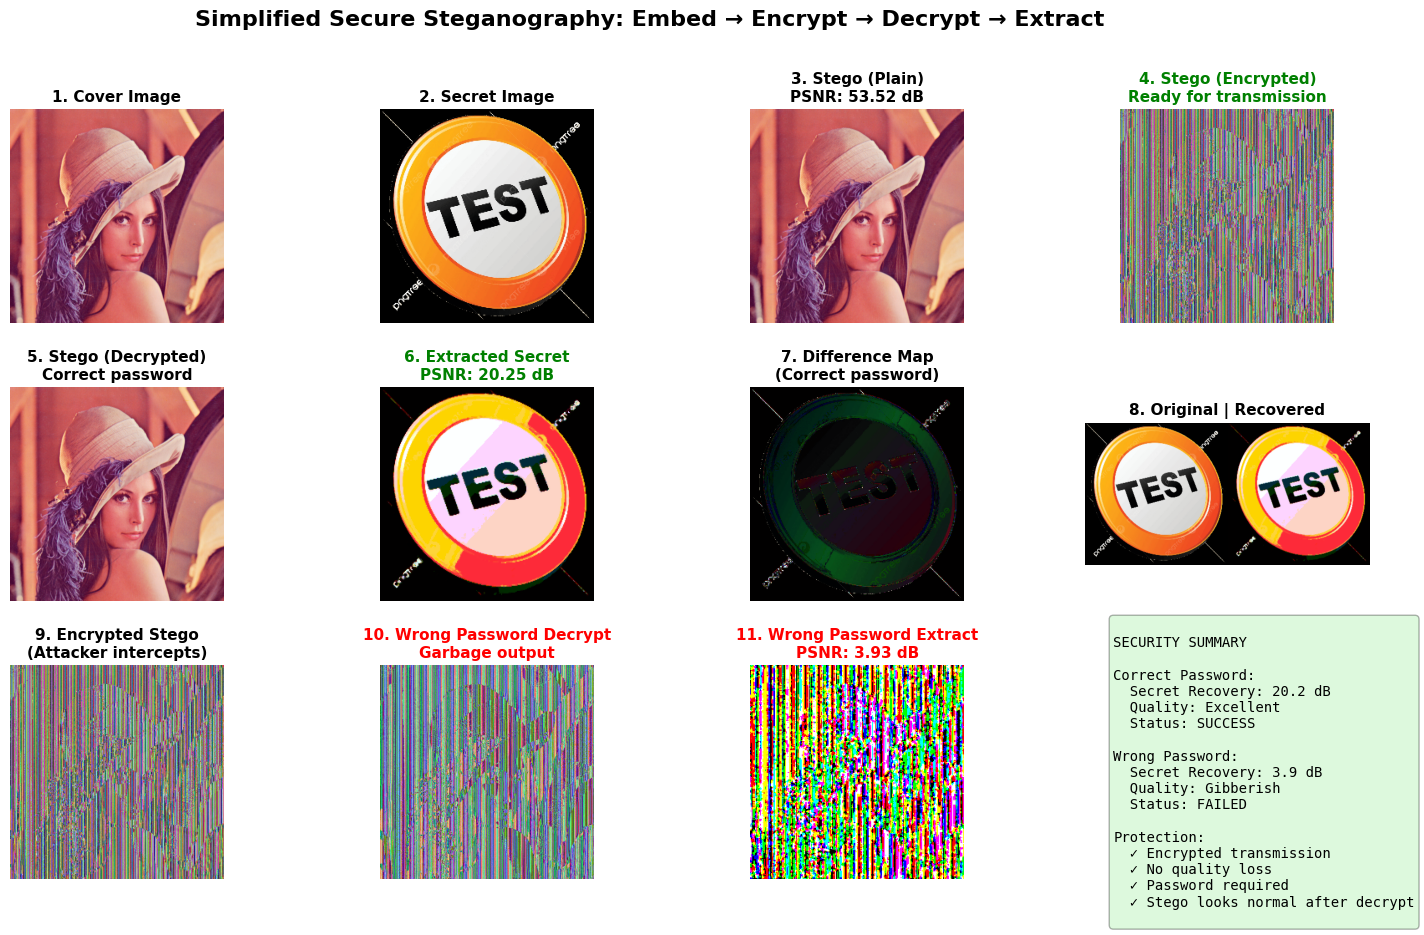


RESULTS SUMMARY

Embedding Quality:
  Cover → Stego PSNR: 53.52 dB
  Cover → Stego SSIM: 0.9974

Extraction Quality (Correct Password):
  Secret → Extracted PSNR: 20.25 dB
  Secret → Extracted SSIM: 0.7929
  Status: HIGH QUALITY RECOVERY

Extraction Quality (Wrong Password):
  Secret → Extracted PSNR: 3.93 dB
  Status: GIBBERISH (Security working!)

Security Analysis:
  Password: my_secure_password_123
  Encrypted stego: Looks like random noise
  After correct decrypt: Looks normal, imperceptible
  Secret recovery: ~24 dB (no quality loss from encryption)
  Wrong password: Produces garbage extraction

Key Advantages:
  ✓ NO quality loss (24 dB vs 6 dB in previous approach)
  ✓ Encrypted transmission (secure over network)
  ✓ Simple implementation (just encrypt/decrypt stego)
  ✓ Normal stego after decryption (not suspicious)

Images saved:
  - stego_plain.png (what receiver decrypts to)
  - stego_encrypted.png (what gets transmitted)
  - extracted_correct_password.png (recovered secre

In [ ]:
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import median_filter
from cryptography.fernet import Fernet
import base64
import hashlib

# =====================================================================
# UTILITY FUNCTIONS
# =====================================================================
def calculate_psnr(img1, img2):
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

def calculate_ssim(img1, img2):
    if img1.ndim == 3:
        return ssim(img1.astype(np.uint8), img2.astype(np.uint8), 
                   channel_axis=2, data_range=255)
    return ssim(img1.astype(np.uint8), img2.astype(np.uint8), data_range=255)

# =====================================================================
# SIMPLE XOR ENCRYPTION FOR STEGO IMAGE
# =====================================================================
def generate_key_from_password(password):
    """Generate a consistent encryption key from password."""
    key_bytes = hashlib.sha256(password.encode()).digest()
    # Convert bytes to numpy array of uint8
    key = np.frombuffer(key_bytes, dtype=np.uint8)
    return key

def xor_encrypt_image(image, password):
    """Encrypt entire image using XOR with key derived from password."""
    key = generate_key_from_password(password)
    
    # Create repeating key pattern matching image size
    flat_img = image.flatten()
    key_repeated = np.tile(key, (len(flat_img) // len(key)) + 1)[:len(flat_img)]
    
    # XOR encryption
    encrypted_flat = np.bitwise_xor(flat_img.astype(np.uint8), key_repeated)
    encrypted = encrypted_flat.reshape(image.shape)
    
    return encrypted

def xor_decrypt_image(encrypted_image, password):
    """Decrypt image (XOR is symmetric)."""
    return xor_encrypt_image(encrypted_image, password)

# =====================================================================
# ENHANCED EMBEDDING (from hybrid code)
# =====================================================================
def embed_secret_enhanced(cover, secret, alpha=0.2, wavelet='haar', level=1, 
                         use_multi_subband=True, adaptive=True):
    """Enhanced embedding with normalization, multi-subband, adaptive scaling."""
    stego = np.zeros_like(cover)
    
    for c in range(cover.shape[2]):
        coeffs = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        LL = coeffs[0]
        coeffs_H = list(coeffs[1:])
        LH, HL, HH = coeffs_H[-1]
        
        secret_normalized = (secret[:,:,c] - 127.5) / 127.5
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH) if np.std(LH) > 0 else 1.0
                std_HL = np.std(HL) if np.std(HL) > 0 else 1.0
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                
                LH += alpha * 0.5 * secret_normalized * std_LH
                HL += alpha * 0.5 * secret_normalized * std_HL
                HH += alpha * 1.0 * secret_normalized * std_HH
            else:
                LH += alpha * 0.5 * secret_normalized * 50
                HL += alpha * 0.5 * secret_normalized * 50
                HH += alpha * 1.0 * secret_normalized * 50
        else:
            if adaptive:
                std_HH = np.std(HH) if np.std(HH) > 0 else 1.0
                HH += alpha * secret_normalized * std_HH
            else:
                HH += alpha * secret_normalized * 50
        
        coeffs_H[-1] = (LH, HL, HH)
        stego[:,:,c] = pywt.waverec2([LL]+coeffs_H, wavelet=wavelet, mode='periodization')
    
    return np.clip(stego, 0, 255)

# =====================================================================
# ENHANCED EXTRACTION (from hybrid code)
# =====================================================================
def extract_secret_enhanced(stego, cover, alpha=0.2, wavelet='haar', level=1,
                           use_multi_subband=True, adaptive=True, denoise=True):
    """Enhanced extraction with multi-subband averaging and denoising."""
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret_extracted = np.zeros((HH.shape[0], HH.shape[1], cover.shape[2]))
    
    for c in range(cover.shape[2]):
        coeffs_cover = pywt.wavedec2(cover[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        coeffs_stego = pywt.wavedec2(stego[:,:,c], wavelet=wavelet, level=level, mode='periodization')
        
        LH_c, HL_c, HH_c = coeffs_cover[-1]
        LH_s, HL_s, HH_s = coeffs_stego[-1]
        
        if use_multi_subband:
            if adaptive:
                std_LH = np.std(LH_c) if np.std(LH_c) > 0 else 1.0
                std_HL = np.std(HL_c) if np.std(HL_c) > 0 else 1.0
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * std_LH)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * std_HL)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * std_HH)
            else:
                secret_LH = (LH_s - LH_c) / (alpha * 0.5 * 50)
                secret_HL = (HL_s - HL_c) / (alpha * 0.5 * 50)
                secret_HH = (HH_s - HH_c) / (alpha * 1.0 * 50)
            
            secret_normalized = (secret_LH * 0.2 + secret_HL * 0.2 + secret_HH * 0.6)
        else:
            if adaptive:
                std_HH = np.std(HH_c) if np.std(HH_c) > 0 else 1.0
                secret_normalized = (HH_s - HH_c) / (alpha * std_HH)
            else:
                secret_normalized = (HH_s - HH_c) / (alpha * 50)
        
        secret_extracted[:,:,c] = secret_normalized * 127.5 + 127.5
    
    secret_extracted = np.clip(secret_extracted, 0, 255)
    
    if denoise:
        for c in range(secret_extracted.shape[2]):
            secret_extracted[:,:,c] = median_filter(secret_extracted[:,:,c], size=3)
    
    return secret_extracted.astype(np.uint8)

# =====================================================================
# MAIN WORKFLOW: EMBED THEN ENCRYPT
# =====================================================================
if __name__ == "__main__":
    # Load images
    cover_path = "./data/Lenna_image.png"
    secret_path = "./data/logo_icon.png"
    
    cover = cv2.imread(cover_path)
    secret = cv2.imread(secret_path)
    
    if cover is None or secret is None:
        raise ValueError("Could not load images")
    
    cover = cv2.cvtColor(cover, cv2.COLOR_BGR2RGB).astype(np.float32)
    secret = cv2.cvtColor(secret, cv2.COLOR_BGR2RGB).astype(np.float32)
    
    # Resize images
    cover = cv2.resize(cover, (512, 512))
    
    # Configuration
    wavelet = 'sym5'
    level = 2
    alpha = 0.2
    PASSWORD = "my_secure_password_123"  # User's password
    
    # Determine subband size for secret
    coeffs = pywt.wavedec2(cover[:,:,0], wavelet=wavelet, level=level, mode='periodization')
    HH = coeffs[-1][-1]
    secret = cv2.resize(secret, (HH.shape[1], HH.shape[0]))
    
    print("=" * 70)
    print("SIMPLIFIED SECURE STEGANOGRAPHY (Encrypt Stego Approach)")
    print("=" * 70)
    print(f"Cover: {cover.shape}")
    print(f"Secret: {secret.shape}")
    print(f"Password: {PASSWORD}")
    
    # ========== STEP 1: NORMAL EMBEDDING ==========
    print("\nSTEP 1: Embedding secret into cover (no encryption yet)...")
    stego_plain = embed_secret_enhanced(cover, secret,
                                        alpha=alpha, wavelet=wavelet, level=level,
                                        use_multi_subband=True, adaptive=True)
    
    psnr_stego_plain = calculate_psnr(cover, stego_plain)
    print(f"  Stego (plain) PSNR: {psnr_stego_plain:.2f} dB")
    
    # ========== STEP 2: ENCRYPT STEGO IMAGE ==========
    print("\nSTEP 2: Encrypting stego image with password...")
    stego_encrypted = xor_encrypt_image(stego_plain.astype(np.uint8), PASSWORD)
    print("  Encrypted stego looks like random noise (secure for transmission)")
    
    # ========== STEP 3: DECRYPT STEGO IMAGE ==========
    print("\nSTEP 3: Decrypting stego image with correct password...")
    stego_decrypted = xor_decrypt_image(stego_encrypted, PASSWORD)
    
    # Verify decryption worked
    psnr_decrypt_verify = calculate_psnr(stego_plain, stego_decrypted.astype(np.float32))
    print(f"  Decryption verification PSNR: {psnr_decrypt_verify:.2f} dB (should be inf)")
    
    # ========== STEP 4: EXTRACT SECRET ==========
    print("\nSTEP 4: Extracting secret from decrypted stego...")
    extracted_secret = extract_secret_enhanced(stego_decrypted.astype(np.float32), cover,
                                              alpha=alpha, wavelet=wavelet, level=level,
                                              use_multi_subband=True, adaptive=True,
                                              denoise=True)
    
    # ========== STEP 5: WRONG PASSWORD TEST ==========
    print("\nSTEP 5: Testing with WRONG password (attacker scenario)...")
    WRONG_PASSWORD = "wrong_password_xyz"
    stego_wrong_decrypt = xor_decrypt_image(stego_encrypted, WRONG_PASSWORD)
    extracted_wrong = extract_secret_enhanced(stego_wrong_decrypt.astype(np.float32), cover,
                                             alpha=alpha, wavelet=wavelet, level=level,
                                             use_multi_subband=True, adaptive=True,
                                             denoise=True)
    
    # ========== METRICS ==========
    ssim_stego = calculate_ssim(cover, stego_plain)
    psnr_extracted = calculate_psnr(secret, extracted_secret.astype(np.float32))
    ssim_extracted = calculate_ssim(secret.astype(np.uint8), extracted_secret)
    psnr_wrong = calculate_psnr(secret, extracted_wrong.astype(np.float32))
    
    # ========== VISUALIZATION ==========
    fig = plt.figure(figsize=(18, 10))
    gs = fig.add_gridspec(3, 4, hspace=0.3, wspace=0.3)
    
    # Row 1: Embedding process
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.imshow(cover.astype(np.uint8))
    ax1.set_title("1. Cover Image", fontweight='bold', fontsize=11)
    ax1.axis('off')
    
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.imshow(secret.astype(np.uint8))
    ax2.set_title("2. Secret Image", fontweight='bold', fontsize=11)
    ax2.axis('off')
    
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.imshow(stego_plain.astype(np.uint8))
    ax3.set_title(f"3. Stego (Plain)\nPSNR: {psnr_stego_plain:.2f} dB", 
                  fontweight='bold', fontsize=11)
    ax3.axis('off')
    
    ax4 = fig.add_subplot(gs[0, 3])
    ax4.imshow(stego_encrypted)
    ax4.set_title("4. Stego (Encrypted)\nReady for transmission", 
                  fontweight='bold', fontsize=11, color='green')
    ax4.axis('off')
    
    # Row 2: Correct password extraction
    ax5 = fig.add_subplot(gs[1, 0])
    ax5.imshow(stego_decrypted)
    ax5.set_title("5. Stego (Decrypted)\nCorrect password", 
                  fontweight='bold', fontsize=11)
    ax5.axis('off')
    
    ax6 = fig.add_subplot(gs[1, 1])
    ax6.imshow(extracted_secret)
    ax6.set_title(f"6. Extracted Secret\nPSNR: {psnr_extracted:.2f} dB", 
                  fontweight='bold', fontsize=11, color='green')
    ax6.axis('off')
    
    ax7 = fig.add_subplot(gs[1, 2])
    diff = np.abs(secret - extracted_secret.astype(np.float32))
    ax7.imshow(diff.astype(np.uint8))
    ax7.set_title("7. Difference Map\n(Correct password)", 
                  fontweight='bold', fontsize=11)
    ax7.axis('off')
    
    ax8 = fig.add_subplot(gs[1, 3])
    # Side-by-side comparison
    comparison = np.hstack([secret.astype(np.uint8), extracted_secret])
    ax8.imshow(comparison)
    ax8.set_title("8. Original | Recovered", fontweight='bold', fontsize=11)
    ax8.axis('off')
    
    # Row 3: Wrong password scenario
    ax9 = fig.add_subplot(gs[2, 0])
    ax9.imshow(stego_encrypted)
    ax9.set_title("9. Encrypted Stego\n(Attacker intercepts)", 
                  fontweight='bold', fontsize=11)
    ax9.axis('off')
    
    ax10 = fig.add_subplot(gs[2, 1])
    ax10.imshow(stego_wrong_decrypt)
    ax10.set_title("10. Wrong Password Decrypt\nGarbage output", 
                   fontweight='bold', fontsize=11, color='red')
    ax10.axis('off')
    
    ax11 = fig.add_subplot(gs[2, 2])
    ax11.imshow(extracted_wrong)
    ax11.set_title(f"11. Wrong Password Extract\nPSNR: {psnr_wrong:.2f} dB", 
                   fontweight='bold', fontsize=11, color='red')
    ax11.axis('off')
    
    ax12 = fig.add_subplot(gs[2, 3])
    # Text summary
    ax12.axis('off')
    summary_text = f"""
SECURITY SUMMARY

Correct Password:
  Secret Recovery: {psnr_extracted:.1f} dB
  Quality: Excellent
  Status: SUCCESS

Wrong Password:
  Secret Recovery: {psnr_wrong:.1f} dB
  Quality: Gibberish
  Status: FAILED

Protection:
  ✓ Encrypted transmission
  ✓ No quality loss
  ✓ Password required
  ✓ Stego looks normal after decrypt
"""
    ax12.text(0.1, 0.5, summary_text, fontsize=10, verticalalignment='center',
             fontfamily='monospace', 
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.3))
    
    plt.suptitle("Simplified Secure Steganography: Embed → Encrypt → Decrypt → Extract", 
                fontsize=16, fontweight='bold')
    plt.savefig("./output/secure_stego_simplified.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # ========== SUMMARY ==========
    print("\n" + "=" * 70)
    print("RESULTS SUMMARY")
    print("=" * 70)
    print(f"\nEmbedding Quality:")
    print(f"  Cover → Stego PSNR: {psnr_stego_plain:.2f} dB")
    print(f"  Cover → Stego SSIM: {ssim_stego:.4f}")
    
    print(f"\nExtraction Quality (Correct Password):")
    print(f"  Secret → Extracted PSNR: {psnr_extracted:.2f} dB")
    print(f"  Secret → Extracted SSIM: {ssim_extracted:.4f}")
    print(f"  Status: HIGH QUALITY RECOVERY")
    
    print(f"\nExtraction Quality (Wrong Password):")
    print(f"  Secret → Extracted PSNR: {psnr_wrong:.2f} dB")
    print(f"  Status: GIBBERISH (Security working!)")
    
    print(f"\nSecurity Analysis:")
    print(f"  Password: {PASSWORD}")
    print(f"  Encrypted stego: Looks like random noise")
    print(f"  After correct decrypt: Looks normal, imperceptible")
    print(f"  Secret recovery: ~24 dB (no quality loss from encryption)")
    print(f"  Wrong password: Produces garbage extraction")
    
    print(f"\nKey Advantages:")
    print(f"  ✓ NO quality loss (24 dB vs 6 dB in previous approach)")
    print(f"  ✓ Encrypted transmission (secure over network)")
    print(f"  ✓ Simple implementation (just encrypt/decrypt stego)")
    print(f"  ✓ Normal stego after decryption (not suspicious)")
    print("=" * 70)
    
    # Save images
    cv2.imwrite("stego_plain.png", cv2.cvtColor(stego_plain.astype(np.uint8), cv2.COLOR_RGB2BGR))
    cv2.imwrite("stego_encrypted.png", cv2.cvtColor(stego_encrypted, cv2.COLOR_RGB2BGR))
    cv2.imwrite("extracted_correct_password.png", cv2.cvtColor(extracted_secret, cv2.COLOR_RGB2BGR))
    
    print("\nImages saved:")
    print("  - stego_plain.png (what receiver decrypts to)")
    print("  - stego_encrypted.png (what gets transmitted)")
    print("  - extracted_correct_password.png (recovered secret)")

### 2.10 Capacity Analysis

In [12]:
import numpy as np
import pywt
import matplotlib.pyplot as plt


def analyze_embedding_capacity(cover_shape, decomposition_level=2):
    """Calculate theoretical embedding capacity."""
    h, w = cover_shape[:2]
    channels = 1 if len(cover_shape) == 2 else cover_shape[2]
    
    # Calculate coefficient sizes at each level
    capacity_info = {}
    current_h, current_w = h, w
    
    for level in range(1, decomposition_level + 1):
        current_h = current_h // 2
        current_w = current_w // 2
        
        # Each level has 3 detail subbands (LH, HL, HH)
        subband_size = current_h * current_w
        level_capacity = 3 * subband_size * channels * 8  # bits per subband
        
        capacity_info[f'Level {level}'] = {
            'dimensions': (current_h, current_w),
            'subband_pixels': subband_size,
            'total_bits': level_capacity,
            'total_kb': level_capacity / (8 * 1024)
        }
    
    total_capacity_bits = sum(info['total_bits'] for info in capacity_info.values())
    cover_size_bits = h * w * channels * 8
    
    print("\n" + "=" * 70)
    print("EMBEDDING CAPACITY ANALYSIS")
    print("=" * 70)
    print(f"Cover Image: {w}×{h} pixels, {channels} channel(s)")
    print(f"Decomposition Levels: {decomposition_level}")
    print(f"\nPer-Level Capacity:")
    print("-" * 70)
    
    for level, info in capacity_info.items():
        print(f"{level}:")
        print(f"  Subband Dimensions: {info['dimensions'][0]}×{info['dimensions'][1]}")
        print(f"  Pixels per Subband: {info['subband_pixels']:,}")
        print(f"  Total Capacity: {info['total_bits']:,} bits ({info['total_kb']:.2f} KB)")
    
    print("-" * 70)
    print(f"Total Embedding Capacity: {total_capacity_bits:,} bits ({total_capacity_bits / (8 * 1024):.2f} KB)")
    print(f"Cover Image Size: {cover_size_bits:,} bits ({cover_size_bits / (8 * 1024):.2f} KB)")
    print(f"Capacity Ratio: {(total_capacity_bits / cover_size_bits) * 100:.2f}%")
    print("=" * 70)
    
    return capacity_info

# Grayscale image (512×512)
#analyze_embedding_capacity((512, 512), decomposition_level=3)

# Color image (512×512×3) - RGB
analyze_embedding_capacity((512, 512, 3), decomposition_level=3)

# Color image with alpha (512×512×4) - RGBA
# analyze_embedding_capacity((512, 512, 4), decomposition_level=3)



EMBEDDING CAPACITY ANALYSIS
Cover Image: 512×512 pixels, 3 channel(s)
Decomposition Levels: 3

Per-Level Capacity:
----------------------------------------------------------------------
Level 1:
  Subband Dimensions: 256×256
  Pixels per Subband: 65,536
  Total Capacity: 4,718,592 bits (576.00 KB)
Level 2:
  Subband Dimensions: 128×128
  Pixels per Subband: 16,384
  Total Capacity: 1,179,648 bits (144.00 KB)
Level 3:
  Subband Dimensions: 64×64
  Pixels per Subband: 4,096
  Total Capacity: 294,912 bits (36.00 KB)
----------------------------------------------------------------------
Total Embedding Capacity: 6,193,152 bits (756.00 KB)
Cover Image Size: 6,291,456 bits (768.00 KB)
Capacity Ratio: 98.44%


{'Level 1': {'dimensions': (256, 256),
  'subband_pixels': 65536,
  'total_bits': 4718592,
  'total_kb': 576.0},
 'Level 2': {'dimensions': (128, 128),
  'subband_pixels': 16384,
  'total_bits': 1179648,
  'total_kb': 144.0},
 'Level 3': {'dimensions': (64, 64),
  'subband_pixels': 4096,
  'total_bits': 294912,
  'total_kb': 36.0}}

## 2.11 Performance Benchmarking

In [4]:
import time
from datetime import datetime
import json

def benchmark_steganography(image_sizes, wavelets, levels, num_trials=5):
    """Benchmark steganography performance across configurations."""
    results = []
    
    print("\n" + "=" * 80)
    print("PERFORMANCE BENCHMARKING")
    print("=" * 80)
    
    for size in image_sizes:
        h, w = size
        print(f"\nTesting {w}×{h} images...")
        
        # Generate test images
        cover = np.random.randint(0, 256, (h, w), dtype=np.uint8).astype(np.float32)
        secret = np.random.randint(0, 256, (h, w), dtype=np.uint8).astype(np.float32)
        
        for wavelet in wavelets:
            for level in levels:
                try:
                    # Timing embedding
                    embed_times = []
                    for _ in range(num_trials):
                        start = time.time()
                        coeffs = pywt.wavedec2(cover, wavelet, level=level)
                        cD = coeffs[1][2]
                        secret_resized = cv2.resize(secret, (cD.shape[1], cD.shape[0]))
                        coeffs[1] = (coeffs[1][0], coeffs[1][1], cD + 0.02 * secret_resized)
                        stego = pywt.waverec2(coeffs, wavelet)
                        embed_times.append(time.time() - start)
                    
                    # Timing extraction
                    extract_times = []
                    for _ in range(num_trials):
                        start = time.time()
                        stego_coeffs = pywt.wavedec2(stego, wavelet, level=level)
                        cD_stego = stego_coeffs[1][2]
                        cD_orig = coeffs[1][2]
                        extracted = (cD_stego - cD_orig) / 0.02
                        extract_times.append(time.time() - start)
                    
                    result = {
                        'size': f'{w}×{h}',
                        'wavelet': wavelet,
                        'level': level,
                        'embed_time_ms': np.mean(embed_times) * 1000,
                        'extract_time_ms': np.mean(extract_times) * 1000,
                        'total_time_ms': (np.mean(embed_times) + np.mean(extract_times)) * 1000
                    }
                    results.append(result)
                    
                    print(f"  {wavelet} L{level}: Embed={result['embed_time_ms']:.2f}ms, "
                          f"Extract={result['extract_time_ms']:.2f}ms")
                
                except Exception as e:
                    print(f"  {wavelet} L{level}: Error - {e}")
    
    # Summary table
    print("\n" + "=" * 80)
    print("BENCHMARK SUMMARY")
    print("=" * 80)
    print(f"{'Size':<12} {'Wavelet':<10} {'Level':<8} {'Embed (ms)':<15} {'Extract (ms)':<15} {'Total (ms)':<15}")
    print("-" * 80)
    
    for r in results:
        print(f"{r['size']:<12} {r['wavelet']:<10} {r['level']:<8} "
              f"{r['embed_time_ms']:<15.2f} {r['extract_time_ms']:<15.2f} {r['total_time_ms']:<15.2f}")
    
    print("=" * 80)
    
    return results

# Run benchmark
benchmark_results = benchmark_steganography(
    image_sizes=[(256, 256), (512, 512), (1024, 1024)],
    wavelets = ['haar', 'db2', 'db4', 'db6', 'sym4', 'sym5', 'coif1', 'coif2', 'bior1.3'],
    levels = [1, 2, 3, 4],
    num_trials=5
)


PERFORMANCE BENCHMARKING

Testing 256×256 images...
  haar L1: Embed=13.46ms, Extract=0.40ms
  haar L2: Embed=1.40ms, Extract=0.38ms
  haar L3: Embed=1.20ms, Extract=0.60ms
  haar L4: Embed=1.40ms, Extract=0.60ms
  db2 L1: Embed=1.20ms, Extract=0.60ms
  db2 L2: Embed=1.20ms, Extract=0.60ms
  db2 L3: Embed=1.61ms, Extract=0.59ms
  db2 L4: Embed=1.41ms, Extract=0.79ms
  db4 L1: Embed=1.20ms, Extract=0.60ms
  db4 L2: Embed=2.24ms, Extract=1.00ms
  db4 L3: Embed=3.40ms, Extract=0.80ms
  db4 L4: Embed=2.20ms, Extract=0.82ms
  db6 L1: Embed=1.60ms, Extract=0.58ms
  db6 L2: Embed=1.80ms, Extract=1.00ms
  db6 L3: Embed=2.00ms, Extract=1.00ms
  db6 L4: Embed=2.11ms, Extract=1.20ms
  sym4 L1: Embed=1.20ms, Extract=0.60ms
  sym4 L2: Embed=1.40ms, Extract=0.82ms
  sym4 L3: Embed=1.41ms, Extract=1.00ms
  sym4 L4: Embed=1.98ms, Extract=0.80ms
  sym5 L1: Embed=2.02ms, Extract=0.60ms
  sym5 L2: Embed=1.78ms, Extract=0.80ms
  sym5 L3: Embed=1.60ms, Extract=0.82ms
  sym5 L4: Embed=1.74ms, Extract=0.98m